          CINEMAPULSE AI — CINEMA INTELLIGENCE SYSTEM

Download complete.
Extracting dataset...

DATASET OVERVIEW
---------------------------------------------
Movies: 9742
Ratings: 100836
Movie columns: ['movieId', 'title', 'genres']
Rating columns: ['userId', 'movieId', 'rating', 'timestamp']

Preparing movie intelligence data...

Prepared movie dataset:


,movieId,title,genres,rating_count,avg_rating,rating_std,release_year,primary_genre,popularity_score
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,215,3.920930,0.834859,1995,Adventure,21.076092
1,2,Jumanji (1995),Adventure|Children|Fantasy,110,3.431818,0.881713,1995,Adventure,16.162251
2,3,Grumpier Old Men (1995),Comedy|Romance,52,3.259615,1.054823,1995,Comedy,12.941625
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,7,2.357143,0.852168,1995,Comedy,4.901541
4,5,Father of the Bride Part II (1995),Comedy,49,3.071429,0.907148,1995,Comedy,12.015499



Generating movie intelligence insights...


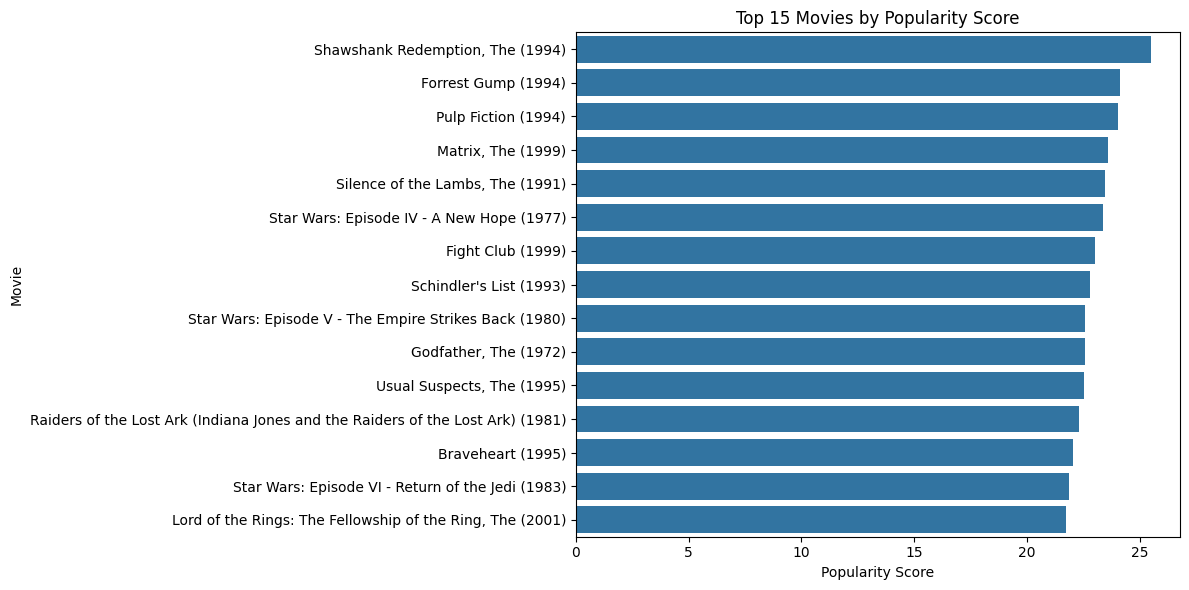

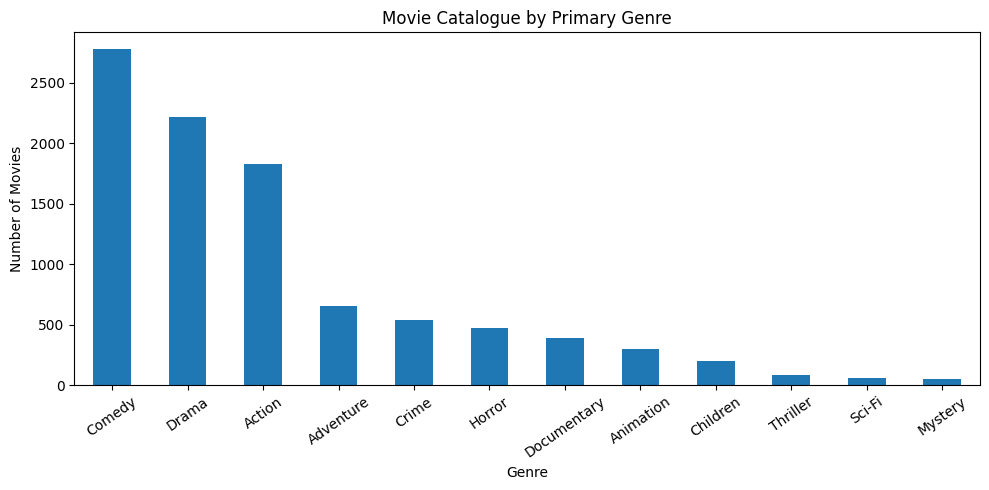

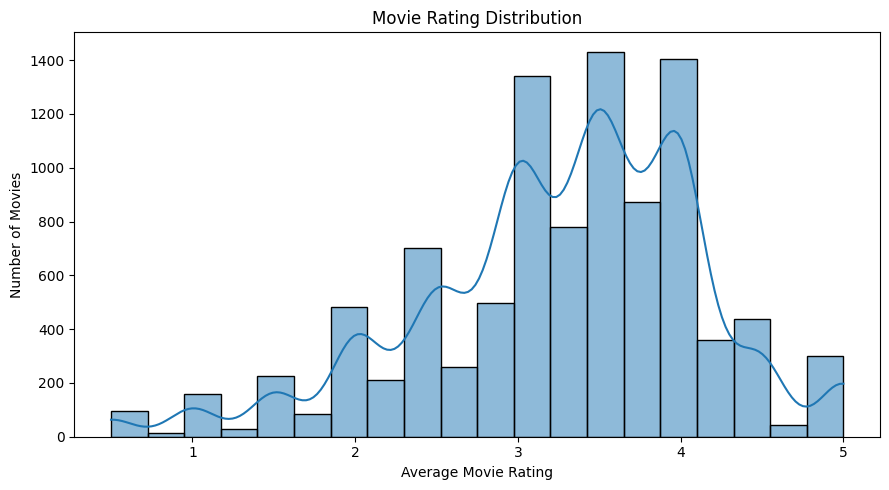


Generating simulated cinema screening records...

Screening dataset created.
Total screening records: 12000


,title,primary_genre,screening_date,show_hour,ticket_price,screen_capacity,occupancy_rate,estimated_revenue
0,Wallace & Gromit: The Wrong Trousers (1993),Animation,2025-12-06,18,140,120,73.99,12460
1,"Mechanic, The (2011)",Action,2025-11-01,15,200,200,50.95,20400
2,Venus (2006),Drama,2025-02-18,9,285,120,25.37,8550
3,Green Card (1990),Comedy,2025-03-21,23,217,180,21.16,8246
4,Santa Claus Is a Stinker (Le Père Noël est une...,Comedy,2026-02-03,12,158,250,21.08,8374



Analyzing cinema demand...


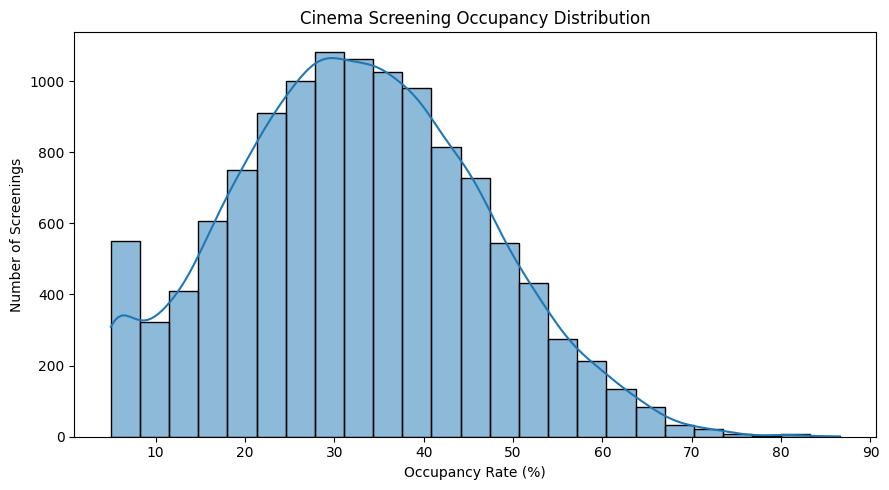

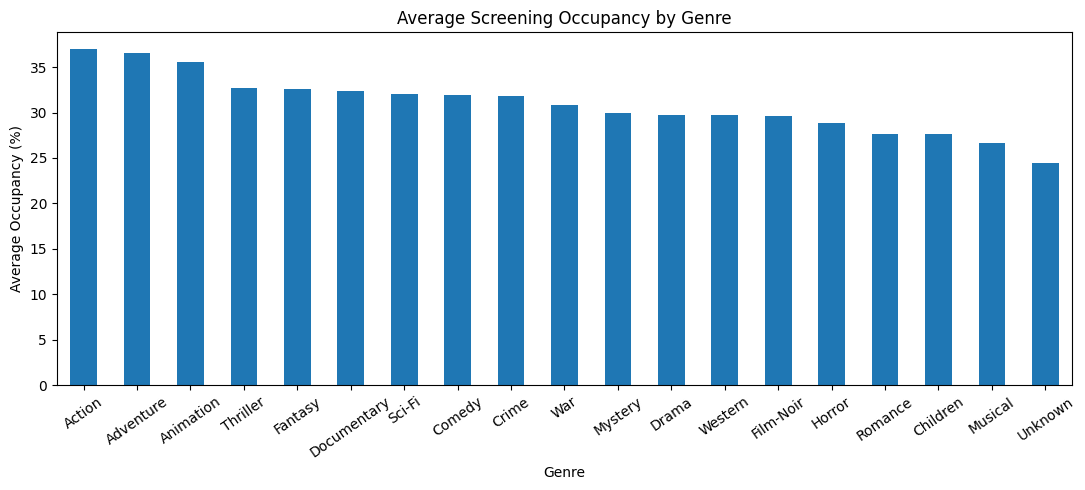

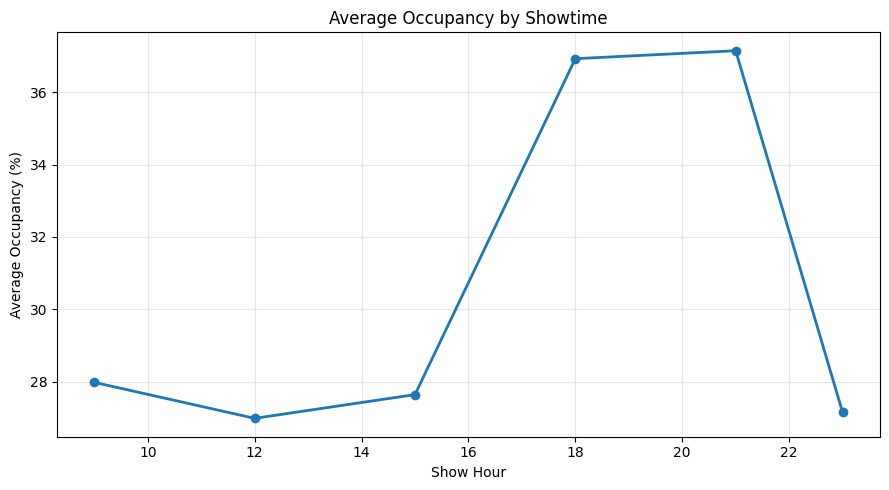


Preparing ML training data...

Training CinemaPulse AI...
Model training completed.

Evaluating model...

MODEL PERFORMANCE
Mean Absolute Error : 6.32 percentage points
Root Mean Squared Error: 7.90 percentage points
R2 Score: 0.6753


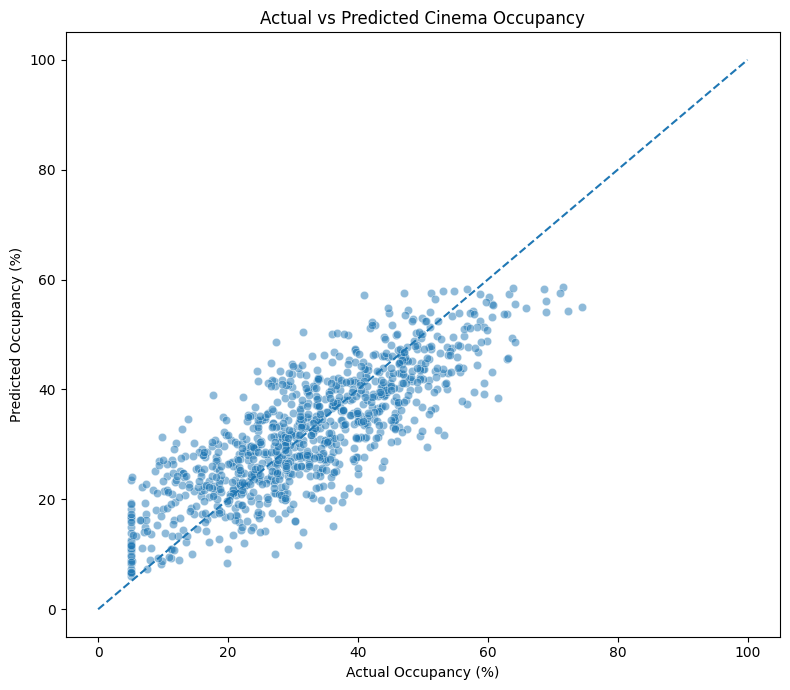


Calculating feature importance...


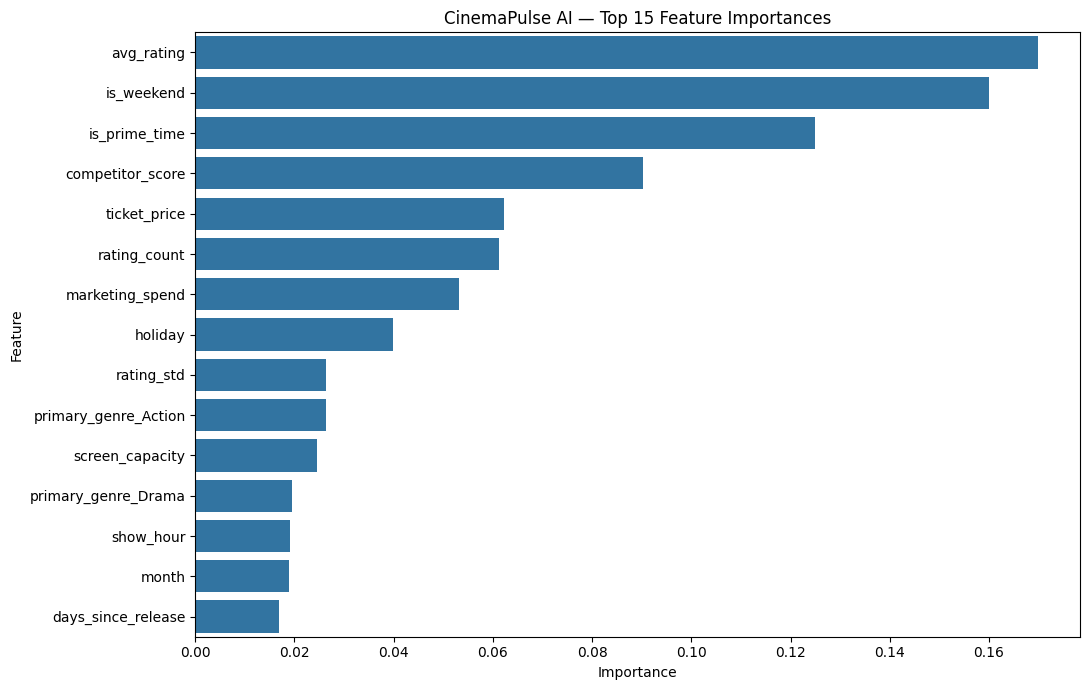

,feature,importance
27,avg_rating,0.169856
31,is_weekend,0.160013
33,is_prime_time,0.124871
37,competitor_score,0.090298
35,ticket_price,0.062204
26,rating_count,0.061217
36,marketing_spend,0.053216
38,holiday,0.039873
28,rating_std,0.026308
0,primary_genre_Action,0.026305



EXAMPLE SCREENING PREDICTION
{
    "movie": "Shawshank Redemption, The (1994)",
    "screening_date": "2026-11-26",
    "showtime": "21:00",
    "predicted_occupancy_percent": 48.02,
    "predicted_occupied_seats": 86,
    "screen_capacity": 180,
    "estimated_ticket_revenue": 18920,
    "demand_category": "Moderate",
    "recommendation": "Consider promotional offers."
}

Generating future screening recommendations...

TOP 20 RECOMMENDED SCREENINGS


,title,showtime,primary_genre,predicted_occupancy,expected_occupied_seats,estimated_revenue,demand_level
0,Star Wars: Episode IV - A New Hope (1977),18:00,Action,51.259473,92,18400,Moderate
1,Star Wars: Episode IV - A New Hope (1977),21:00,Action,50.943627,92,18400,Moderate
2,Star Wars: Episode VI - Return of the Jedi (1983),18:00,Action,51.004500,92,18400,Moderate
3,Raiders of the Lost Ark (Indiana Jones and the...,21:00,Action,51.103893,92,18400,Moderate
4,Raiders of the Lost Ark (Indiana Jones and the...,18:00,Action,51.286293,92,18400,Moderate
5,Star Wars: Episode V - The Empire Strikes Back...,18:00,Action,51.245573,92,18400,Moderate
6,Star Wars: Episode V - The Empire Strikes Back...,21:00,Action,50.968853,92,18400,Moderate
7,Fight Club (1999),18:00,Action,50.905487,92,18400,Moderate
8,Saving Private Ryan (1998),18:00,Action,51.005920,92,18400,Moderate
9,Fight Club (1999),21:00,Action,50.796627,91,18200,Moderate



Generating revenue analytics...


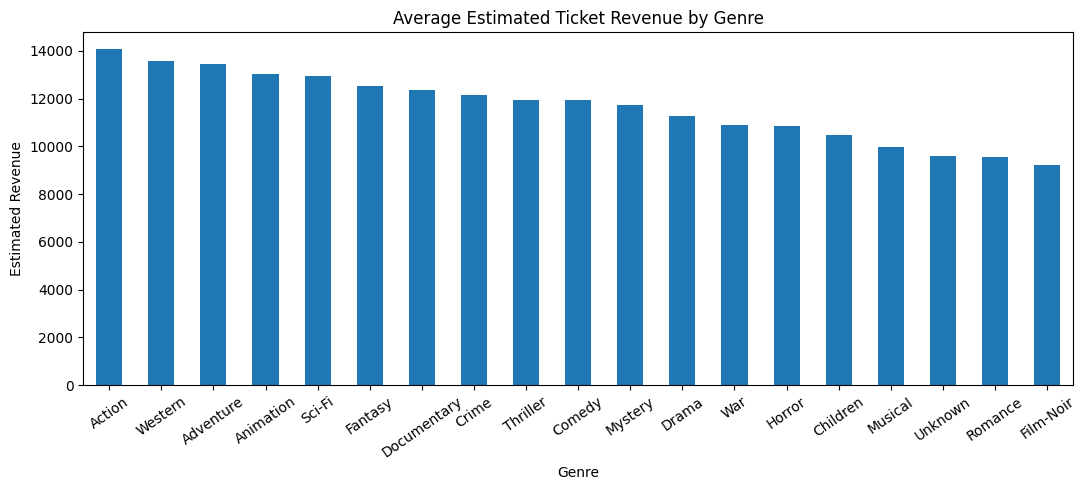

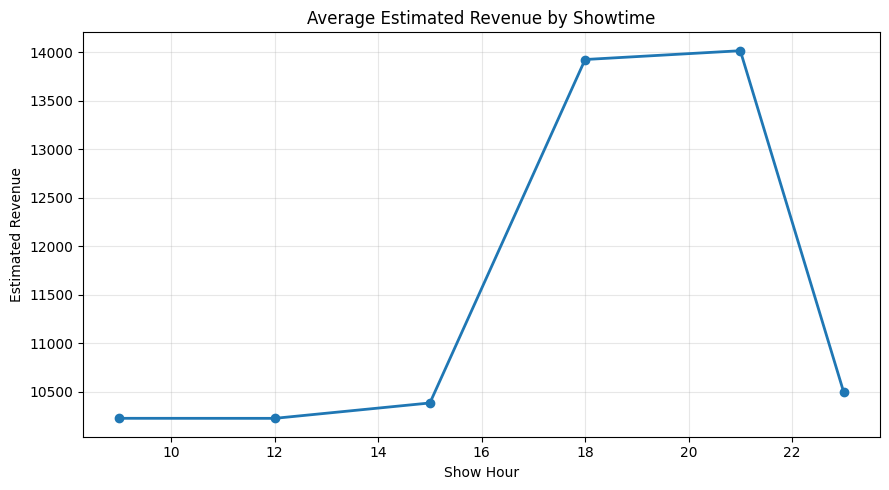


CINEMAPULSE BUSINESS SUMMARY
total_movies_analyzed: 9724
total_rating_records: 100836
simulated_screenings: 12000
average_simulated_occupancy: 32.47
average_estimated_screening_revenue: 12243.33
total_simulated_gross_revenue: 146919974.0
top_genre_by_average_occupancy: Action
top_recommended_movie: Star Wars: Episode IV - A New Hope (1977)
top_recommended_showtime: 18:00
model_metrics: {'MAE': 6.315, 'RMSE': 7.897, 'R2_Score': 0.6753, 'Training_Records': 9600, 'Testing_Records': 2400}
data_note: MovieLens ratings and genres are real. Cinema occupancy, ticket prices, marketing spend, competition and revenue are simulated.

Trained model saved: /content/CinemaPulse_AI/models/cinemapulse_occupancy_model.pkl

PROJECT FILE INVENTORY
README.md | 2.29 KB
data/movielens/ml-latest-small/README.txt | 8.15 KB
data/movielens/ml-latest-small/links.csv | 193.34 KB
data/movielens/ml-latest-small/movies.csv | 482.84 KB
data/movielens/ml-latest-small/ratings.csv | 2425.51 KB
data/movielens/ml-latest-s

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ================================================================

!pip -q install pandas numpy matplotlib seaborn scikit-learn joblib requests

import os
import re
import json
import zipfile
import warnings
import requests
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from datetime import timedelta
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.inspection import permutation_importance
from IPython.display import display
from google.colab import files

warnings.filterwarnings("ignore")
np.random.seed(42)

# ================================================================
# 1. PROJECT CONFIGURATION
# ================================================================

PROJECT = Path("/content/CinemaPulse_AI")

DATA_DIR = PROJECT / "data"
OUTPUT_DIR = PROJECT / "outputs"
MODEL_DIR = PROJECT / "models"
REPORT_DIR = PROJECT / "reports"
PLOT_DIR = OUTPUT_DIR / "visualizations"

for folder in [DATA_DIR, OUTPUT_DIR, MODEL_DIR, REPORT_DIR, PLOT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("          CINEMAPULSE AI — CINEMA INTELLIGENCE SYSTEM")
print("=" * 65)

# ================================================================
# 2. AUTOMATIC MOVIELENS DATASET DOWNLOAD
# ================================================================

DATA_URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
ZIP_PATH = DATA_DIR / "movielens.zip"
EXTRACT_DIR = DATA_DIR / "movielens"

if not (EXTRACT_DIR / "ml-latest-small" / "movies.csv").exists():

    print("\nDownloading MovieLens dataset...")

    response = requests.get(DATA_URL, timeout=120)
    response.raise_for_status()

    with open(ZIP_PATH, "wb") as f:
        f.write(response.content)

    print("Download complete.")
    print("Extracting dataset...")

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_DIR)

else:
    print("\nMovieLens dataset already exists.")

MOVIE_FILE = EXTRACT_DIR / "ml-latest-small" / "movies.csv"
RATING_FILE = EXTRACT_DIR / "ml-latest-small" / "ratings.csv"

movies = pd.read_csv(MOVIE_FILE)
ratings = pd.read_csv(RATING_FILE)

print("\nDATASET OVERVIEW")
print("-" * 45)
print("Movies:", len(movies))
print("Ratings:", len(ratings))
print("Movie columns:", list(movies.columns))
print("Rating columns:", list(ratings.columns))

# ================================================================
# 3. MOVIE DATA PREPARATION
# ================================================================

print("\nPreparing movie intelligence data...")

movie_stats = ratings.groupby("movieId").agg(
    rating_count=("rating", "count"),
    avg_rating=("rating", "mean"),
    rating_std=("rating", "std")
).reset_index()

movie_stats["rating_std"] = movie_stats["rating_std"].fillna(0)

movie_data = movies.merge(
    movie_stats,
    on="movieId",
    how="inner"
)

movie_data["rating_count"] = movie_data["rating_count"].astype(int)

def extract_year(title):
    match = re.search(r"\((\d{4})\)", str(title))
    return int(match.group(1)) if match else 2000

movie_data["release_year"] = movie_data["title"].apply(extract_year)

def get_primary_genre(genre_string):
    genres = str(genre_string).split("|")
    genres = [g for g in genres if g not in ["(no genres listed)", "nan"]]
    return genres[0] if genres else "Unknown"

movie_data["primary_genre"] = movie_data["genres"].apply(get_primary_genre)

movie_data["popularity_score"] = (
    np.log1p(movie_data["rating_count"]) *
    movie_data["avg_rating"]
)

movie_data = movie_data.replace([np.inf, -np.inf], np.nan)
movie_data = movie_data.dropna(
    subset=["rating_count", "avg_rating", "release_year"]
)

movie_data.to_csv(DATA_DIR / "prepared_movie_data.csv", index=False)

print("\nPrepared movie dataset:")
display(movie_data.head())

# ================================================================
# 4. MOVIE INTELLIGENCE EXPLORATION
# ================================================================

print("\nGenerating movie intelligence insights...")

top_movies = movie_data.sort_values(
    "popularity_score", ascending=False
).head(15)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_movies,
    x="popularity_score",
    y="title"
)
plt.title("Top 15 Movies by Popularity Score")
plt.xlabel("Popularity Score")
plt.ylabel("Movie")
plt.tight_layout()
plt.savefig(PLOT_DIR / "top_popular_movies.png", dpi=150)
plt.show()

genre_counts = (
    movie_data["primary_genre"]
    .value_counts()
    .head(12)
)

plt.figure(figsize=(10, 5))
genre_counts.plot(kind="bar")
plt.title("Movie Catalogue by Primary Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig(PLOT_DIR / "genre_distribution.png", dpi=150)
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(movie_data["avg_rating"], bins=20, kde=True)
plt.title("Movie Rating Distribution")
plt.xlabel("Average Movie Rating")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.savefig(PLOT_DIR / "rating_distribution.png", dpi=150)
plt.show()

# ================================================================
# 5. GENERATE CINEMA SCREENING DATA
# ================================================================
# Important:
# MovieLens does not provide actual theatre occupancy.
# Screening-level occupancy is simulated for this project.
# This allows us to demonstrate the complete ML workflow.

print("\nGenerating simulated cinema screening records...")

N_SCREENINGS = 12000

rng = np.random.default_rng(42)

selected_indices = rng.integers(
    0,
    len(movie_data),
    size=N_SCREENINGS
)

screenings = movie_data.iloc[selected_indices].reset_index(drop=True)

# Generate screening dates
start_date = pd.Timestamp("2025-01-01")
end_date = pd.Timestamp("2026-10-31")

date_range = (end_date - start_date).days

screenings["screening_date"] = [
    start_date + pd.Timedelta(days=int(x))
    for x in rng.integers(0, date_range + 1, N_SCREENINGS)
]

screenings["day_of_week"] = screenings["screening_date"].dt.day_name()
screenings["month"] = screenings["screening_date"].dt.month
screenings["is_weekend"] = (
    screenings["screening_date"].dt.dayofweek >= 5
).astype(int)

# Showtime distribution
screenings["show_hour"] = rng.choice(
    [9, 12, 15, 18, 21, 23],
    size=N_SCREENINGS,
    p=[0.08, 0.13, 0.18, 0.27, 0.25, 0.09]
)

screenings["is_prime_time"] = screenings["show_hour"].isin(
    [18, 21]
).astype(int)

screenings["screen_capacity"] = rng.choice(
    [100, 120, 150, 180, 200, 250],
    size=N_SCREENINGS
)

screenings["ticket_price"] = rng.integers(
    120, 351, N_SCREENINGS
)

screenings["marketing_spend"] = rng.integers(
    1000, 50001, N_SCREENINGS
)

screenings["competitor_score"] = rng.uniform(
    0, 1, N_SCREENINGS
)

screenings["holiday"] = rng.choice(
    [0, 1],
    size=N_SCREENINGS,
    p=[0.90, 0.10]
)

screenings["days_since_release"] = np.clip(
    (2026 - screenings["release_year"]) * 365 +
    rng.integers(0, 366, N_SCREENINGS),
    0,
    12000
)

# Normalize popularity and marketing
popularity_norm = (
    np.log1p(screenings["rating_count"]) /
    np.log1p(movie_data["rating_count"].max())
)

rating_signal = (screenings["avg_rating"] - 3.0) / 2.0

marketing_signal = screenings["marketing_spend"] / 50000

freshness_signal = np.exp(
    -screenings["days_since_release"] / 1500
)

genre_boost = screenings["primary_genre"].map({
    "Action": 0.09,
    "Adventure": 0.08,
    "Animation": 0.07,
    "Comedy": 0.05,
    "Drama": 0.01,
    "Thriller": 0.06,
    "Horror": 0.05,
    "Romance": 0.02,
    "Sci-Fi": 0.07,
    "Crime": 0.03,
    "Fantasy": 0.06
}).fillna(0.02)

weekend_boost = screenings["is_weekend"] * 0.12
prime_boost = screenings["is_prime_time" ] * 0.10
holiday_boost = screenings["holiday"] * 0.09

price_penalty = (
    (screenings["ticket_price"] - 120) / 230
) * 0.10

competition_penalty = screenings["competitor_score"] * 0.13

capacity_penalty = (
    (screenings["screen_capacity"] - 100) / 150
) * 0.035

# Screening occupancy simulation
occupancy_signal = (
    0.19
    + popularity_norm * 0.18
    + rating_signal * 0.13
    + marketing_signal * 0.10
    + freshness_signal * 0.12
    + genre_boost
    + weekend_boost
    + prime_boost
    + holiday_boost
    - price_penalty
    - competition_penalty
    - capacity_penalty
    + rng.normal(0, 0.075, N_SCREENINGS)
)

# Occupancy as percentage
screenings["occupancy_rate"] = np.clip(
    occupancy_signal * 100,
    5,
    100
).round(2)

screenings["occupied_seats"] = np.round(
    screenings["screen_capacity"] *
    screenings["occupancy_rate"] / 100
).astype(int)

screenings["estimated_revenue"] = (
    screenings["occupied_seats"] *
    screenings["ticket_price"]
)

screenings["demand_category"] = pd.cut(
    screenings["occupancy_rate"],
    bins=[0, 35, 60, 80, 100.01],
    labels=["Low", "Moderate", "High", "Very High"]
)

screenings["screening_date"] = pd.to_datetime(
    screenings["screening_date"]
)

screenings.to_csv(
    DATA_DIR / "simulated_cinema_screenings.csv",
    index=False
)

print("\nScreening dataset created.")
print("Total screening records:", len(screenings))

display(
    screenings[
        [
            "title",
            "primary_genre",
            "screening_date",
            "show_hour",
            "ticket_price",
            "screen_capacity",
            "occupancy_rate",
            "estimated_revenue"
        ]
    ].head()
)

# ================================================================
# 6. EXPLORATORY CINEMA ANALYTICS
# ================================================================

print("\nAnalyzing cinema demand...")

plt.figure(figsize=(9, 5))
sns.histplot(
    screenings["occupancy_rate"],
    bins=25,
    kde=True
)
plt.title("Cinema Screening Occupancy Distribution")
plt.xlabel("Occupancy Rate (%)")
plt.ylabel("Number of Screenings")
plt.tight_layout()
plt.savefig(PLOT_DIR / "occupancy_distribution.png", dpi=150)
plt.show()

genre_occupancy = (
    screenings.groupby("primary_genre", observed=True)
    ["occupancy_rate"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 5))
genre_occupancy.plot(kind="bar")
plt.title("Average Screening Occupancy by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Occupancy (%)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig(PLOT_DIR / "genre_occupancy.png", dpi=150)
plt.show()

hour_occupancy = (
    screenings.groupby("show_hour")["occupancy_rate"]
    .mean()
)

plt.figure(figsize=(9, 5))
hour_occupancy.plot(marker="o", linewidth=2)
plt.title("Average Occupancy by Showtime")
plt.xlabel("Show Hour")
plt.ylabel("Average Occupancy (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR / "showtime_occupancy.png", dpi=150)
plt.show()

# ================================================================
# 7. PREPARE MACHINE LEARNING DATA
# ================================================================

print("\nPreparing ML training data...")

FEATURES = [
    "rating_count",
    "avg_rating",
    "rating_std",
    "release_year",
    "primary_genre",
    "day_of_week",
    "month",
    "is_weekend",
    "show_hour",
    "is_prime_time",
    "screen_capacity",
    "ticket_price",
    "marketing_spend",
    "competitor_score",
    "holiday",
    "days_since_release"
]

TARGET = "occupancy_rate"

X = screenings[FEATURES].copy()
y = screenings[TARGET].copy()

# Chronological split: older screenings train the model;
# newer screenings are reserved for testing.
sorted_indices = screenings["screening_date"].sort_values().index

split_index = int(len(sorted_indices) * 0.80)

train_indices = sorted_indices[:split_index]
test_indices = sorted_indices[split_index:]

X_train = X.loc[train_indices]
X_test = X.loc[test_indices]

y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

categorical_features = [
    "primary_genre",
    "day_of_week"
]

numeric_features = [
    col for col in FEATURES
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

# ================================================================
# 8. TRAIN CINEMAPULSE AI MODEL
# ================================================================

print("\nTraining CinemaPulse AI...")

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            ExtraTreesRegressor(
                n_estimators=250,
                max_depth=22,
                min_samples_split=4,
                min_samples_leaf=2,
                max_features=0.9,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

model.fit(X_train, y_train)

print("Model training completed.")

# ================================================================
# 9. MODEL EVALUATION
# ================================================================

print("\nEvaluating model...")

predictions = model.predict(X_test)
predictions = np.clip(predictions, 0, 100)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

metrics = {
    "MAE": round(float(mae), 3),
    "RMSE": round(float(rmse), 3),
    "R2_Score": round(float(r2), 4),
    "Training_Records": int(len(X_train)),
    "Testing_Records": int(len(X_test))
}

print("\nMODEL PERFORMANCE")
print("=" * 45)
print(f"Mean Absolute Error : {mae:.2f} percentage points")
print(f"Root Mean Squared Error: {rmse:.2f} percentage points")
print(f"R2 Score: {r2:.4f}")

with open(REPORT_DIR / "model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# ================================================================
# 10. ACTUAL VS PREDICTED OCCUPANCY
# ================================================================

comparison = pd.DataFrame({
    "Actual_Occupancy": y_test.values,
    "Predicted_Occupancy": predictions
})

comparison.to_csv(
    REPORT_DIR / "actual_vs_predicted.csv",
    index=False
)

plt.figure(figsize=(8, 7))
sns.scatterplot(
    data=comparison.sample(
        min(1000, len(comparison)),
        random_state=42
    ),
    x="Actual_Occupancy",
    y="Predicted_Occupancy",
    alpha=0.5
)

plt.plot([0, 100], [0, 100], linestyle="--")
plt.title("Actual vs Predicted Cinema Occupancy")
plt.xlabel("Actual Occupancy (%)")
plt.ylabel("Predicted Occupancy (%)")
plt.tight_layout()
plt.savefig(PLOT_DIR / "actual_vs_predicted.png", dpi=150)
plt.show()

# ================================================================
# 11. FEATURE IMPORTANCE
# ================================================================

print("\nCalculating feature importance...")

trained_regressor = model.named_steps["regressor"]
trained_encoder = model.named_steps["preprocessor"]

encoded_names = (
    list(
        trained_encoder
        .named_transformers_["categorical"]
        .get_feature_names_out(categorical_features)
    )
    + numeric_features
)

importance_df = pd.DataFrame({
    "feature": encoded_names,
    "importance": trained_regressor.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
)

importance_df.to_csv(
    REPORT_DIR / "feature_importance.csv",
    index=False
)

plt.figure(figsize=(11, 7))
sns.barplot(
    data=importance_df.head(15),
    x="importance",
    y="feature"
)
plt.title("CinemaPulse AI — Top 15 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(PLOT_DIR / "feature_importance.png", dpi=150)
plt.show()

display(importance_df.head(15))

# ================================================================
# 12. CINEMA SCREENING PREDICTION FUNCTION
# ================================================================

def predict_screening(
    movie_title,
    show_hour=18,
    screening_date="2026-11-26",
    ticket_price=200,
    screen_capacity=180,
    marketing_spend=15000,
    competitor_score=0.30,
    holiday=0
):
    """
    Predict occupancy and estimated gross ticket revenue
    for a selected movie and screening configuration.
    """

    movie_match = movie_data[
        movie_data["title"].str.lower() ==
        movie_title.lower()
    ]

    if movie_match.empty:
        raise ValueError(
            "Movie not found. Choose a title from movie_data."
        )

    movie = movie_match.iloc[0]
    date = pd.Timestamp(screening_date)

    record = pd.DataFrame([{
        "rating_count": movie["rating_count"],
        "avg_rating": movie["avg_rating"],
        "rating_std": movie["rating_std"],
        "release_year": movie["release_year"],
        "primary_genre": movie["primary_genre"],
        "day_of_week": date.day_name(),
        "month": date.month,
        "is_weekend": int(date.dayofweek >= 5),
        "show_hour": show_hour,
        "is_prime_time": int(show_hour in [18, 21]),
        "screen_capacity": screen_capacity,
        "ticket_price": ticket_price,
        "marketing_spend": marketing_spend,
        "competitor_score": competitor_score,
        "holiday": holiday,
        "days_since_release": max(
            0,
            (date.year - int(movie["release_year"])) * 365
            + date.dayofyear
        )
    }])[FEATURES]

    predicted_occupancy = float(
        np.clip(model.predict(record)[0], 0, 100)
    )

    predicted_seats = int(
        round(screen_capacity * predicted_occupancy / 100)
    )

    predicted_revenue = predicted_seats * ticket_price

    if predicted_occupancy >= 80:
        demand = "Very High"
        recommendation = "Consider adding another screening."
    elif predicted_occupancy >= 60:
        demand = "High"
        recommendation = "Good screening opportunity."
    elif predicted_occupancy >= 35:
        demand = "Moderate"
        recommendation = "Consider promotional offers."
    else:
        demand = "Low"
        recommendation = "Consider changing the showtime."

    return {
        "movie": movie_title,
        "screening_date": str(date.date()),
        "showtime": f"{show_hour}:00",
        "predicted_occupancy_percent": round(predicted_occupancy, 2),
        "predicted_occupied_seats": predicted_seats,
        "screen_capacity": screen_capacity,
        "estimated_ticket_revenue": predicted_revenue,
        "demand_category": demand,
        "recommendation": recommendation
    }

# ================================================================
# 13. EXAMPLE MOVIE SCREENING PREDICTION
# ================================================================

example_movie = (
    movie_data.sort_values(
        "popularity_score",
        ascending=False
    ).iloc[0]["title"]
)

print("\nEXAMPLE SCREENING PREDICTION")
print("=" * 50)

example_prediction = predict_screening(
    movie_title=example_movie,
    show_hour=21,
    screening_date="2026-11-26",
    ticket_price=220,
    screen_capacity=180,
    marketing_spend=20000,
    competitor_score=0.25,
    holiday=0
)

print(json.dumps(example_prediction, indent=4))

with open(REPORT_DIR / "example_prediction.json", "w") as f:
    json.dump(example_prediction, f, indent=4)

# ================================================================
# 14. AUTOMATED SHOWTIME RECOMMENDATION ENGINE
# ================================================================

print("\nGenerating future screening recommendations...")

future_date = pd.Timestamp("2026-11-26")

candidate_movies = (
    movie_data.sort_values(
        "popularity_score",
        ascending=False
    ).head(30)
)

candidate_rows = []

for _, movie in candidate_movies.iterrows():

    for hour in [12, 15, 18, 21]:

         candidate_rows.append({
            "movieId": movie["movieId"],
            "title": movie["title"],
            "rating_count": movie["rating_count"],
            "avg_rating": movie["avg_rating"],
            "rating_std": movie["rating_std"],
            "release_year": movie["release_year"],
            "primary_genre": movie["primary_genre"],
            "day_of_week": future_date.day_name(),
            "month": future_date.month,
            "is_weekend": int(future_date.dayofweek >= 5),
            "show_hour": hour,
            "is_prime_time": int(hour in [18, 21]),
            "screen_capacity": 180,
            "ticket_price": 200 if hour in [18, 21] else 160,
            "marketing_spend": 18000,
            "competitor_score": 0.25,
            "holiday": 0,
            "days_since_release": max(
                0,
                (future_date.year - int(movie["release_year"])) * 365
                + future_date.dayofyear
            )
        })

recommendations = pd.DataFrame(candidate_rows)

recommendations["predicted_occupancy"] = np.clip(
    model.predict(recommendations[FEATURES]),
    0,
    100
)

recommendations["expected_occupied_seats"] = np.round(
    recommendations["screen_capacity" ] *
    recommendations["predicted_occupancy"] / 100
).astype(int)

recommendations["estimated_revenue"] = (
    recommendations["expected_occupied_seats"] *
    recommendations["ticket_price"]
)

recommendations["showtime"] = (
    recommendations["show_hour"].astype(str) + ":00"
)

recommendations["demand_level"] = pd.cut(
    recommendations["predicted_occupancy"],
    bins=[0, 35, 60, 80, 100.01],
    labels=["Low", "Moderate", "High", "Very High"]
)

recommendations = recommendations.sort_values(
    "estimated_revenue",
    ascending=False
)

recommendations.to_csv(
    OUTPUT_DIR / "recommended_screening_schedule.csv",
    index=False
)

print("\nTOP 20 RECOMMENDED SCREENINGS")
display(
    recommendations[
        [
            "title",
            "showtime",
            "primary_genre",
            "predicted_occupancy",
            "expected_occupied_seats",
            "estimated_revenue",
            "demand_level"
        ]
    ].head(20).reset_index(drop=True)
)

# ================================================================
# 15. REVENUE INTELLIGENCE
# ================================================================

print("\nGenerating revenue analytics...")

revenue_by_genre = (
    screenings.groupby("primary_genre", observed=True)
    ["estimated_revenue"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 5))
revenue_by_genre.plot(kind="bar")
plt.title("Average Estimated Ticket Revenue by Genre")
plt.xlabel("Genre")
plt.ylabel("Estimated Revenue")
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig(PLOT_DIR / "revenue_by_genre.png", dpi=150)
plt.show()

revenue_by_hour = (
    screenings.groupby("show_hour")
    ["estimated_revenue"]
    .mean()
)

plt.figure(figsize=(9, 5))
revenue_by_hour.plot(marker="o", linewidth=2)
plt.title("Average Estimated Revenue by Showtime")
plt.xlabel("Show Hour")
plt.ylabel("Estimated Revenue")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR / "revenue_by_showtime.png", dpi=150)
plt.show()

# ================================================================
# 16. CINEMAPULSE BUSINESS SUMMARY
# ================================================================

business_summary = {
    "total_movies_analyzed": int(len(movie_data)),
    "total_rating_records": int(len(ratings)),
    "simulated_screenings": int(len(screenings)),
    "average_simulated_occupancy": round(
        float(screenings["occupancy_rate"].mean()), 2
    ),
    "average_estimated_screening_revenue": round(
        float(screenings["estimated_revenue"].mean()), 2
    ),
    "total_simulated_gross_revenue": round(
        float(screenings["estimated_revenue"].sum()), 2
    ),
    "top_genre_by_average_occupancy": str(
        genre_occupancy.index[0]
    ),
    "top_recommended_movie": str(
        recommendations.iloc[0]["title"]
    ),
    "top_recommended_showtime": str(
        recommendations.iloc[0]["showtime"]
    ),
    "model_metrics": metrics,
    "data_note": (
        "MovieLens ratings and genres are real. "
        "Cinema occupancy, ticket prices, marketing spend, "
        "competition and revenue are simulated."
    )
}

with open(REPORT_DIR / "business_summary.json", "w") as f:
    json.dump(business_summary, f, indent=4)

print("\nCINEMAPULSE BUSINESS SUMMARY")
print("=" * 55)

for key, value in business_summary.items():
    print(f"{key}: {value}")

# ================================================================
# 17. SAVE TRAINED MODEL
# ================================================================

MODEL_PATH = MODEL_DIR / "cinemapulse_occupancy_model.pkl"

joblib.dump(model, MODEL_PATH)

print("\nTrained model saved:", MODEL_PATH)

# ================================================================
# 18. CREATE PROJECT README
# ================================================================

readme = r"""
# CinemaPulse AI

AI-powered cinema demand intelligence and screening occupancy
prediction system.

## Project Overview

CinemaPulse AI analyzes movie ratings and genres, predicts
simulated screening occupancy, estimates ticket revenue and
recommends screening schedules.

## Features

- Automatic MovieLens dataset download
- Movie popularity analysis
- Genre-based analytics
- Cinema occupancy prediction
- Revenue estimation
- Showtime demand analysis
- Screening schedule recommendations
- Extra Trees regression
- Model evaluation and feature importance
- Exportable reports and visualizations

## Technology Stack

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- ExtraTreesRegressor
- Joblib
- Google Colab

## Dataset

MovieLens latest-small:
https://grouplens.org/datasets/movielens/latest/

MovieLens provides real movie metadata, genres and user ratings.

## Important Data Limitation

MovieLens does not contain actual cinema attendance, theatre
occupancy, ticket sales or revenue.

Therefore, the screening-level data in this project is simulated.
The occupancy prediction model learns patterns from this simulated
dataset. Its evaluation metrics must not be interpreted as
real-world cinema forecasting performance.

## Model

ExtraTreesRegressor is used to predict screening occupancy
percentage from movie, schedule and operational features.

## Outputs

- Prepared movie data
- Simulated cinema screening records
- Occupancy prediction model
- Model evaluation metrics
- Actual versus predicted plot
- Feature importance plot
- Genre and showtime analytics
- Screening schedule recommendations
- Business summary

## Run

Open the notebook in Google Colab and run all cells.

No manual dataset upload or API key is required.

## Future Enhancements

- Integrate real theatre ticket booking data
- Add real-world holiday calendars
- Integrate regional movie release data
- Build a live cinema analytics dashboard
- Optimize showtime allocation across multiple screens
- Train using actual historical occupancy records

## Disclaimer

This is an educational and portfolio project.
Predicted occupancy and revenue are estimates based on simulated
screening records, not validated commercial forecasts.

## Dataset Attribution

MovieLens dataset by GroupLens Research.
https://grouplens.org/datasets/movielens/
"""

with open(PROJECT / "README.md", "w") as f:
    f.write(readme)

# ================================================================
# 19. PROJECT FILE INVENTORY
# ================================================================

print("\nPROJECT FILE INVENTORY")
print("=" * 55)

for path in sorted(PROJECT.rglob("*")):
    if path.is_file():
        print(
            str(path.relative_to(PROJECT)),
            "|",
            round(path.stat().st_size / 1024, 2),
            "KB"
        )

# ================================================================
# 20. ZIP COMPLETE PROJECT
# ================================================================

import shutil

ZIP_PATH = shutil.make_archive(
    "/content/CinemaPulse_AI_Day14",
    "zip",
    root_dir=PROJECT
)

print("\n" + "=" * 65)
print("       CINEMAPULSE AI — PROJECT EXECUTION COMPLETED")
print("=" * 65)

print("Project folder:", PROJECT)
print("ZIP package:", ZIP_PATH)
print("Model:", MODEL_PATH)
print("README:", PROJECT / "README.md")

print("\nDownloading complete project package...")

files.download(ZIP_PATH)

       CINEMAPULSE AI — ADVANCED DECISION ENGINE

1. Calculating permutation feature importance...


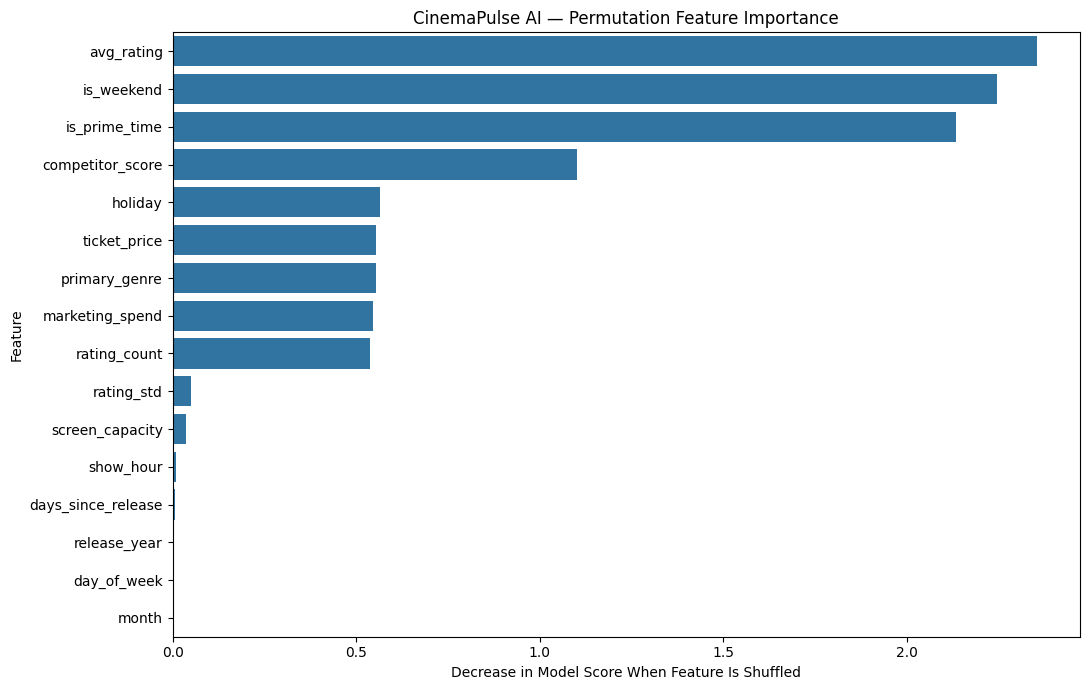

,feature,importance_mean,importance_std
1,avg_rating,2.354446,0.050980
7,is_weekend,2.246005,0.037779
9,is_prime_time,2.135412,0.090874
13,competitor_score,1.102169,0.062007
14,holiday,0.565040,0.018332
11,ticket_price,0.554781,0.037011
4,primary_genre,0.552980,0.017158
12,marketing_spend,0.544800,0.054865
0,rating_count,0.536782,0.023178
2,rating_std,0.048856,0.013705



2. Analyzing model performance by demand category...


,actual_demand,records,MAE,average_actual,average_predicted
0,Low,1382.0,5.970179,23.091910,26.067686
1,Moderate,950.0,6.429538,44.217663,39.971983
2,High,66.0,11.578015,64.525758,52.969026
3,Very High,2.0,16.815866,80.705000,63.889134


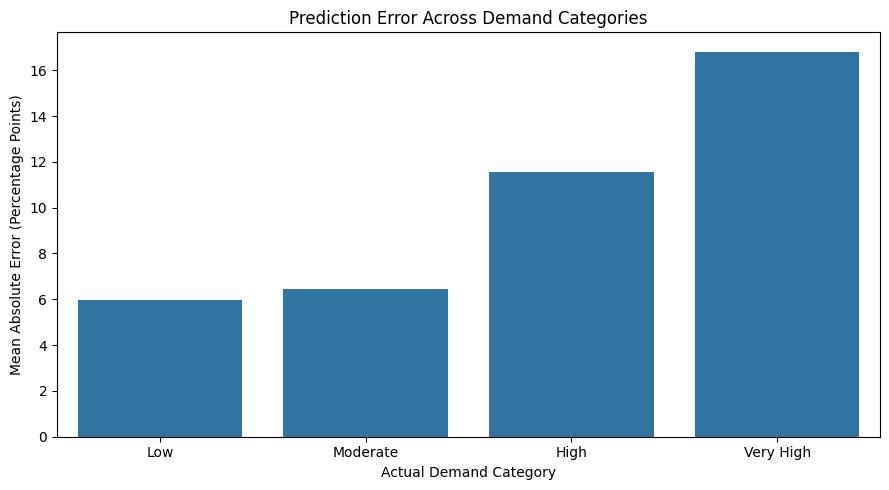


3. Running ticket price sensitivity simulation...

WHAT-IF SIMULATION RESULTS
Movie: Shawshank Redemption, The (1994)


,movie,showtime,ticket_price,predicted_occupancy,predicted_seats,estimated_revenue
23,"Shawshank Redemption, The (1994)",21:00,320,44.266069,80,25600
17,"Shawshank Redemption, The (1994)",18:00,320,43.603253,78,24960
22,"Shawshank Redemption, The (1994)",21:00,280,45.379509,82,22960
16,"Shawshank Redemption, The (1994)",18:00,280,44.707039,80,22400
21,"Shawshank Redemption, The (1994)",21:00,240,47.170202,85,20400
15,"Shawshank Redemption, The (1994)",18:00,240,46.600802,84,20160
11,"Shawshank Redemption, The (1994)",15:00,320,32.036578,58,18560
5,"Shawshank Redemption, The (1994)",12:00,320,31.443135,57,18240
20,"Shawshank Redemption, The (1994)",21:00,200,48.309469,87,17400
10,"Shawshank Redemption, The (1994)",15:00,280,33.741471,61,17080


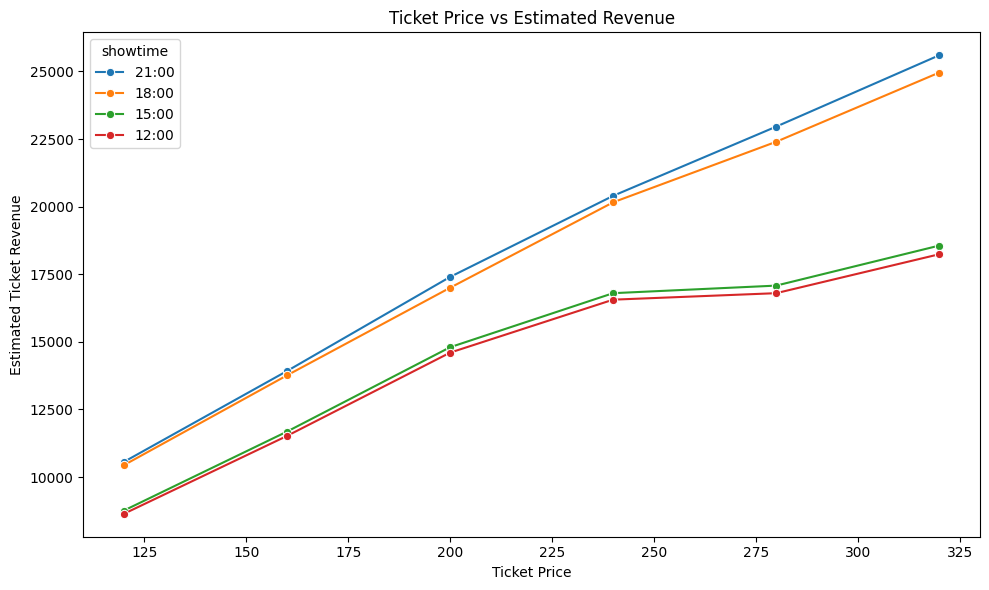


4. Optimizing screening configurations...

TOP OPTIMIZED SCREENING CONFIGURATIONS


,movie,genre,recommended_showtime,recommended_ticket_price,predicted_occupancy,predicted_seats,estimated_revenue
5,Star Wars: Episode IV - A New Hope (1977),Action,21:00,300,47.03,85,25500
3,"Matrix, The (1999)",Action,21:00,300,46.74,84,25200
6,Fight Club (1999),Action,21:00,300,46.75,84,25200
11,Raiders of the Lost Ark (Indiana Jones and the...,Action,21:00,300,46.81,84,25200
8,Star Wars: Episode V - The Empire Strikes Back...,Action,21:00,300,46.75,84,25200
13,Star Wars: Episode VI - Return of the Jedi (1983),Action,21:00,300,46.33,83,24900
12,Braveheart (1995),Action,21:00,300,45.78,82,24600
9,"Godfather, The (1972)",Crime,21:00,300,44.39,80,24000
10,"Usual Suspects, The (1995)",Crime,21:00,300,44.36,80,24000
4,"Silence of the Lambs, The (1991)",Crime,21:00,300,44.57,80,24000


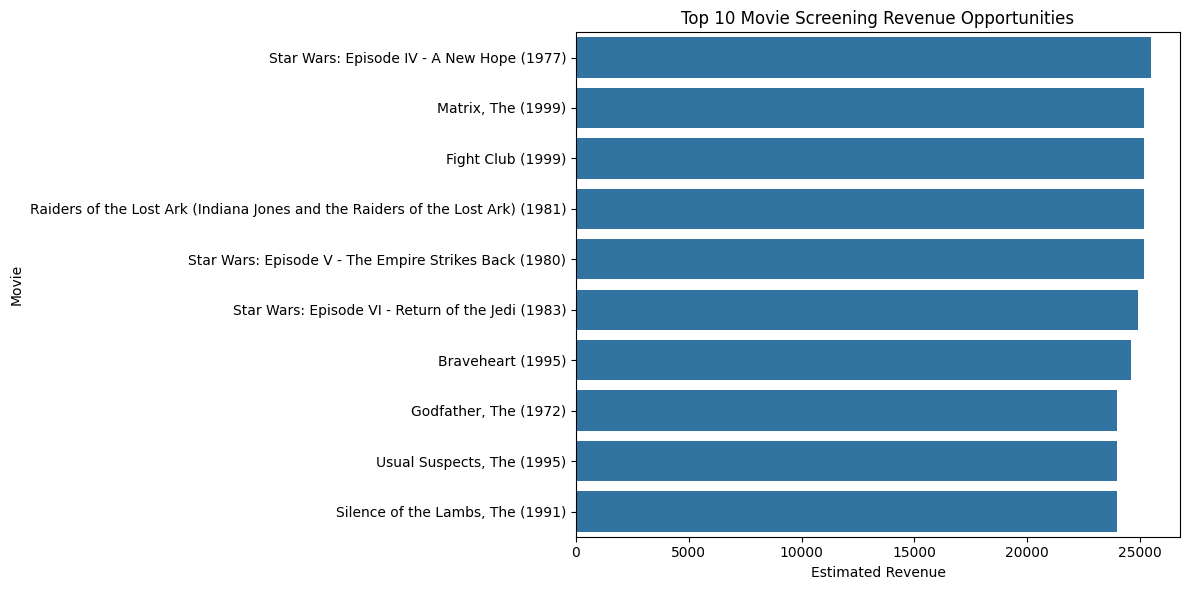


5. Generating business recommendations...
{
    "highest_revenue_opportunity": {
        "movie": "Star Wars: Episode IV - A New Hope (1977)",
        "showtime": "21:00",
        "ticket_price": 300,
        "predicted_occupancy": 47.03,
        "estimated_revenue": 25500
    },
    "highest_average_occupancy_hour": "21",
    "highest_average_occupancy_genre": "Action",
    "business_note": "These are model-based recommendations using simulated cinema screening data, not validated real-world forecasts."
}

       CINEMAPULSE AI ADVANCED UPGRADE COMPLETE
Advanced reports: /content/CinemaPulse_AI/advanced
Visualizations: /content/CinemaPulse_AI/outputs/visualizations
Complete project ZIP: /content/CinemaPulse_AI_Day14_Advanced.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


All advanced modules completed.


In [3]:

# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib

from pathlib import Path
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

print("=" * 65)
print("       CINEMAPULSE AI — ADVANCED DECISION ENGINE")
print("=" * 65)

# ------------------------------------------------
# 1. VERIFY PREVIOUS PROJECT VARIABLES
# ------------------------------------------------

required = [
    "model", "movie_data", "screenings",
    "X_test", "y_test", "FEATURES",
    "PROJECT", "OUTPUT_DIR", "REPORT_DIR", "PLOT_DIR"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Previous project cells are missing: " + ", ".join(missing)
    )

ADVANCED_DIR = PROJECT / "advanced"
ADVANCED_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 2. PERMUTATION FEATURE IMPORTANCE
# ------------------------------------------------

print("\n1. Calculating permutation feature importance...")

perm = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

permutation_df.to_csv(
    ADVANCED_DIR / "permutation_feature_importance.csv",
    index=False
)

plt.figure(figsize=(11, 7))
sns.barplot(
    data=permutation_df,
    x="importance_mean",
    y="feature"
)
plt.title("CinemaPulse AI — Permutation Feature Importance")
plt.xlabel("Decrease in Model Score When Feature Is Shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(
    PLOT_DIR / "permutation_feature_importance.png",
    dpi=150
)
plt.show()

display(permutation_df)

# ------------------------------------------------
# 3. DEMAND-LEVEL MODEL ERROR ANALYSIS
# ------------------------------------------------

print("\n2. Analyzing model performance by demand category...")

evaluation_df = pd.DataFrame({
    "actual_occupancy": y_test.values,
    "predicted_occupancy": np.clip(
        model.predict(X_test), 0, 100
    )
})

evaluation_df["actual_demand"] = pd.cut(
    evaluation_df["actual_occupancy"],
    bins=[0, 35, 60, 80, 100.01],
    labels=["Low", "Moderate", "High", "Very High"]
)

demand_error = (
    evaluation_df.groupby("actual_demand", observed=True)
    .apply(
        lambda x: pd.Series({
            "records": len(x),
            "MAE": mean_absolute_error(
                x["actual_occupancy"],
                x["predicted_occupancy"]
            ),
            "average_actual": x["actual_occupancy"].mean(),
            "average_predicted": x["predicted_occupancy"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

demand_error.to_csv(
    ADVANCED_DIR / "demand_level_error_analysis.csv",
    index=False
)

display(demand_error)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=demand_error,
    x="actual_demand",
    y="MAE"
)
plt.title("Prediction Error Across Demand Categories")
plt.xlabel("Actual Demand Category")
plt.ylabel("Mean Absolute Error (Percentage Points)")
plt.tight_layout()
plt.savefig(
    PLOT_DIR / "demand_level_model_error.png",
    dpi=150
)
plt.show()

# ------------------------------------------------
# 4. WHAT-IF TICKET PRICE SIMULATOR
# ------------------------------------------------

print("\n3. Running ticket price sensitivity simulation...")

def cinema_what_if(
    movie_title,
    show_date="2026-11-26",
    show_hours=(12, 15, 18, 21),
    ticket_prices=(120, 160, 200, 240, 280, 320),
    capacity=180,
    marketing=20000,
    competition=0.25,
    holiday=0
):

    matches = movie_data[
        movie_data["title"].str.lower() == movie_title.lower()
    ]

    if matches.empty:
        raise ValueError("Movie not found in movie_data.")

    movie = matches.iloc[0]
    date = pd.Timestamp(show_date)

    rows = []

    for hour in show_hours:
        for price in ticket_prices:

            row = {
                "rating_count": movie["rating_count"],
                "avg_rating": movie["avg_rating"],
                "rating_std": movie["rating_std"],
                "release_year": movie["release_year"],
                "primary_genre": movie["primary_genre"],
                "day_of_week": date.day_name(),
                "month": date.month,
                "is_weekend": int(date.dayofweek >= 5),
                "show_hour": hour,
                "is_prime_time": int(hour in [18, 21]),
                "screen_capacity": capacity,
                "ticket_price": price,
                "marketing_spend": marketing,
                "competitor_score": competition,
                "holiday": holiday,
                "days_since_release": max(
                    0,
                    (date.year - int(movie["release_year"])) * 365
                    + date.dayofyear
                )
            }

            rows.append(row)

    scenario_df = pd.DataFrame(rows)

    scenario_df["predicted_occupancy"] = np.clip(
        model.predict(scenario_df[FEATURES]),
        0,
        100
    )

    scenario_df["predicted_seats"] = np.round(
        scenario_df["screen_capacity"] *
        scenario_df["predicted_occupancy"] / 100
    ).astype(int)

    scenario_df["estimated_revenue"] = (
        scenario_df["predicted_seats"] *
        scenario_df["ticket_price"]
    )

    scenario_df["showtime"] = (
        scenario_df["show_hour"].astype(str) + ":00"
    )

    scenario_df["movie"] = movie_title

    return scenario_df.sort_values(
        "estimated_revenue",
        ascending=False
    )


# Run a sample simulation
sample_movie = (
    movie_data.sort_values(
        "popularity_score",
        ascending=False
    ).iloc[0]["title"]
)

what_if_results = cinema_what_if(sample_movie)

what_if_results.to_csv(
    ADVANCED_DIR / "what_if_price_simulation.csv",
    index=False
)

print("\nWHAT-IF SIMULATION RESULTS")
print("Movie:", sample_movie)

display(
    what_if_results[
        [
            "movie",
            "showtime",
            "ticket_price",
            "predicted_occupancy",
            "predicted_seats",
            "estimated_revenue"
        ]
    ].head(15)
)

# ------------------------------------------------
# 5. PRICE VS REVENUE VISUALIZATION
# ------------------------------------------------

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=what_if_results,
    x="ticket_price",
    y="estimated_revenue",
    hue="showtime",
    marker="o"
)

plt.title("Ticket Price vs Estimated Revenue")
plt.xlabel("Ticket Price")
plt.ylabel("Estimated Ticket Revenue")
plt.tight_layout()
plt.savefig(
    PLOT_DIR / "ticket_price_revenue_sensitivity.png",
    dpi=150
)
plt.show()

# ------------------------------------------------
# 6. SCREENING REVENUE OPTIMIZER
# ------------------------------------------------

print("\n4. Optimizing screening configurations...")

top_movies = (
    movie_data.sort_values(
        "popularity_score",
        ascending=False
    ).head(15)
)

optimized_rows = []

for _, movie in top_movies.iterrows():

    scenarios = cinema_what_if(
        movie_title=movie["title"],
        show_date="2026-11-26",
        show_hours=(12, 15, 18, 21),
        ticket_prices=(140, 180, 220, 260, 300),
        capacity=180,
        marketing=20000,
        competition=0.25
    )

    best = scenarios.iloc[0]

    optimized_rows.append({
        "movie": movie["title"],
        "genre": movie["primary_genre"],
        "recommended_showtime": best["showtime"],
        "recommended_ticket_price": int(best["ticket_price"]),
        "predicted_occupancy": round(
            float(best["predicted_occupancy"]), 2
        ),
        "predicted_seats": int(best["predicted_seats"]),
        "estimated_revenue": int(best["estimated_revenue"])
    })

optimized_df = pd.DataFrame(optimized_rows)

optimized_df = optimized_df.sort_values(
    "estimated_revenue",
    ascending=False
)

optimized_df.to_csv(
    ADVANCED_DIR / "optimized_movie_screenings.csv",
    index=False
)

print("\nTOP OPTIMIZED SCREENING CONFIGURATIONS")

display(optimized_df)

# ------------------------------------------------
# 7. OPTIMIZATION VISUALIZATION
# ------------------------------------------------

plt.figure(figsize=(12, 6))

sns.barplot(
    data=optimized_df.head(10),
    x="estimated_revenue",
    y="movie"
)

plt.title("Top 10 Movie Screening Revenue Opportunities")
plt.xlabel("Estimated Revenue")
plt.ylabel("Movie")
plt.tight_layout()
plt.savefig(
    PLOT_DIR / "optimized_screening_revenue.png",
    dpi=150
)
plt.show()

# ------------------------------------------------
# 8. BUSINESS DECISION ENGINE
# ------------------------------------------------

print("\n5. Generating business recommendations...")

best_overall = optimized_df.iloc[0]

best_hour = (
    screenings.groupby("show_hour")["occupancy_rate"]
    .mean()
    .sort_values(ascending=False)
)

best_genre = (
    screenings.groupby("primary_genre", observed=True)
    ["occupancy_rate"]
    .mean()
    .sort_values(ascending=False)
)

decisions = {
    "highest_revenue_opportunity": {
        "movie": str(best_overall["movie"]),
        "showtime": str(best_overall["recommended_showtime"]),
        "ticket_price": int(
            best_overall["recommended_ticket_price"]
        ),
        "predicted_occupancy": float(
            best_overall["predicted_occupancy"]
        ),
        "estimated_revenue": int(
            best_overall["estimated_revenue"]
        )
    },
    "highest_average_occupancy_hour": str(best_hour.index[0]),
    "highest_average_occupancy_genre": str(best_genre.index[0]),
    "business_note": (
        "These are model-based recommendations using simulated "
        "cinema screening data, not validated real-world forecasts."
    )
}

with open(
    ADVANCED_DIR / "business_decision_report.json",
    "w"
) as f:
    json.dump(decisions, f, indent=4)

print(json.dumps(decisions, indent=4))

# ------------------------------------------------
# 9. SAVE ADVANCED PROJECT SUMMARY
# ------------------------------------------------

advanced_summary = {
    "project": "CinemaPulse AI",
    "advanced_modules": [
        "Permutation feature importance",
        "Demand-level error analysis",
        "Ticket price sensitivity simulator",
        "Screening revenue optimizer",
        "Business decision engine"
    ],
    "permutation_top_features": (
        permutation_df.head(5)["feature"].tolist()
    ),
    "best_screening": decisions["highest_revenue_opportunity"],
    "evaluation": {
        "overall_MAE": float(
            mean_absolute_error(y_test, model.predict(X_test))
        )
    }
}

with open(
    ADVANCED_DIR / "advanced_project_summary.json",
    "w"
) as f:
    json.dump(advanced_summary, f, indent=4)

# ------------------------------------------------
# 10. SAVE UPDATED MODEL AND ZIP
# ------------------------------------------------

joblib.dump(
    model,
    MODEL_DIR / "cinemapulse_occupancy_model.pkl"
)

import shutil

zip_path = shutil.make_archive(
    "/content/CinemaPulse_AI_Day14_Advanced",
    "zip",
    root_dir=PROJECT
)

print("\n" + "=" * 65)
print("       CINEMAPULSE AI ADVANCED UPGRADE COMPLETE")
print("=" * 65)

print("Advanced reports:", ADVANCED_DIR)
print("Visualizations:", PLOT_DIR)
print("Complete project ZIP:", zip_path)

from google.colab import files
files.download(zip_path)

print("\nAll advanced modules completed.")
